In [1]:
import json
import pickle
from datetime import datetime
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import (adjusted_rand_score, calinski_harabasz_score,
                             davies_bouldin_score, silhouette_score)
from sklearn.preprocessing import StandardScaler
while ROOT != ROOT.parent and not (ROOT / "src" / "clases_po").exists():
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT / "src"))
from clases_po import HFDatasetLoader
from clases_po import Reportes


/home/runner/work/ML_EA3_iudigital/ML_EA3_iudigital/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Etapa 1 · Extracción  → escena 2
Todas las ventas de una tienda online del Reino Unido (artículos de regalo, muchos clientes mayoristas),
de diciembre de 2009 a diciembre de 2011. UCI Online Retail II, publicado en Hugging Face.

In [2]:
loader = HFDatasetLoader(dataset_name="psabino/precios_de_viviendas_madrid", split="train",
                         filename="datos/precios_de_viviendas_madrid.csv")
df_crudo = loader.load()   # 1 · cargar

# se eliminan datos de las url que no son relevantes para el analisis
df_crudo = df_crudo.drop(
    columns=["url_listado"]
)
# se imprime una muestra del dataset
df_crudo.head()

Generating train split:   0%|          | 0/915 [00:00<?, ? examples/s]

Generating train split: 100%|██████████| 915/915 [00:00<00:00, 27577.05 examples/s]

,url,titulo,id,precio,baños,habitaciones,metros_cuadrados,descripcion,direccion,tipologia,nombre_anunciante_profesional,nombre_anunciante
0,https://www.idealista.com/inmueble/104027174/,Piso en venta en calle de Villanueva,104027174,1920000,3,3,183,Residencia única con acabados de la más alta c...,"Recoletos, Madrid",Pisos,Promora Madrid,Promora Madrid
1,https://www.idealista.com/inmueble/102321942/,Piso en venta en calle de Núñez de Balboa,102321942,1995000,3,3,170,"Preciosa reforma a estrenar, con terrazas y ga...","Castellana, Madrid",Pisos,Madrid MMC,Engel & Völkers Madrid
2,https://www.idealista.com/inmueble/103334142/,Piso en venta en Conde Orgaz-Piovera,103334142,1300000,3,4,270,DE SALAS CONSULTORES INMOBILIARIOS MAV02679 le...,"Hortaleza, Madrid",Pisos,De Salas Consultores Inmobiliarios,De Salas Consultores Inmobiliarios
3,https://www.idealista.com/inmueble/104161987/,Piso en venta en Nueva España,104161987,1650000,3,3,248,Gilmar Real Estate vende espectacular piso en ...,"Chamartín, Madrid",Pisos,departamento comercial,Gilmar Viso - Chamartín
4,https://www.idealista.com/inmueble/103989666/,Piso en venta en calle de Claudio Coello,103989666,1590750,3,3,116,Descubre esta impresionante vivienda exterior ...,"Recoletos, Madrid",Pisos,Walter Haus Salamanca,Walter Haus Madrid


In [3]:
df_crudo.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 915 entries, 0 to 914
Data columns (total 12 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   url                            915 non-null    object
 1   titulo                         915 non-null    object
 2   id                             915 non-null    int64 
 3   precio                         915 non-null    int64 
 4   baños                          915 non-null    int64 
 5   habitaciones                   915 non-null    int64 
 6   metros_cuadrados               915 non-null    int64 
 7   descripcion                    914 non-null    object
 8   direccion                      915 non-null    object
 9   tipologia                      915 non-null    object
 10  nombre_anunciante_profesional  915 non-null    object
 11  nombre_anunciante              915 non-null    object
dtypes: int64(5), object(7)
memory usage: 85.9+ KB


In [4]:
# se crea un dataset copia con base al crudo para procesamiento de datos
df = df_crudo.copy()
df.info()
# se revisan si hay pisos repetidos segun su url
print("pisos distintos segun sitio web:", df["url"].nunique())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 915 entries, 0 to 914
Data columns (total 12 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   url                            915 non-null    object
 1   titulo                         915 non-null    object
 2   id                             915 non-null    int64 
 3   precio                         915 non-null    int64 
 4   baños                          915 non-null    int64 
 5   habitaciones                   915 non-null    int64 
 6   metros_cuadrados               915 non-null    int64 
 7   descripcion                    914 non-null    object
 8   direccion                      915 non-null    object
 9   tipologia                      915 non-null    object
 10  nombre_anunciante_profesional  915 non-null    object
 11  nombre_anunciante              915 non-null    object
dtypes: int64(5), object(7)
memory usage: 85.9+ KB
pisos distintos se

In [5]:
pisos_por_anunciante = df.groupby("nombre_anunciante").size()
print(pisos_por_anunciante.describe().round(1))

count    118.0
mean       7.8
std       15.3
min        1.0
25%        1.0
50%        2.0
75%        8.0
max      134.0
dtype: float64


## Etapa 2 · Preprocesamiento  → escena 3
### 2.1 Validar antes de confiar
Cada validación produce una **métrica** y una **decisión**. Para los problemas que se excluyen,
reportamos también cuánto dinero representan.

In [6]:


tabla_validacion = pd.DataFrame({
    "Columna": df.columns,
    "Tipo Dato": df.dtypes.values,
    "Nulos": df.isnull().sum().values,
    "Nulos (%)": (
        df.isnull().sum() / len(df) * 100
    ).round(2).values,
    "Valores Únicos": [
        df[col].nunique()
        for col in df.columns
    ]
})

tabla_validacion

,Columna,Tipo Dato,Nulos,Nulos (%),Valores Únicos
0,url,object,0,0.00,915
1,titulo,object,0,0.00,551
2,id,int64,0,0.00,915
3,precio,int64,0,0.00,393
4,baños,int64,0,0.00,12
5,habitaciones,int64,0,0.00,13
6,metros_cuadrados,int64,0,0.00,351
7,descripcion,object,1,0.11,907
8,direccion,object,0,0.00,105
9,tipologia,object,0,0.00,2


In [7]:
#precios sospechosos

# Detectar registros con precio por metro cuadrado sospechoso

sospechosos = df.loc[
    (
        (df["precio"] / df["metros_cuadrados"] < 2000)
        |
        (df["precio"] / df["metros_cuadrados"] > 50000000)
    ),
    ["id", "precio", "metros_cuadrados"]
].copy()

# Mostrar el cálculo únicamente en la salida
sospechosos["precio_m2"] = (
    sospechosos["precio"] /
    sospechosos["metros_cuadrados"]
).round(2)

display(sospechosos)



,id,precio,metros_cuadrados,precio_m2
215,104156897,229000,118,1940.68
362,102998789,180000,92,1956.52
403,102020886,375000,313,1198.08
429,103713270,299000,154,1941.56
466,97659976,239900,157,1528.03
788,103628504,2900000,1768,1640.27
825,104179896,2900000,1768,1640.27
906,97957477,210000,153,1372.55


# 3. Selección de Variables para el Modelo

Para la construcción del modelo K-Means se seleccionan las variables numéricas más representativas de los inmuebles. Estas variables contienen información relacionada con el valor económico y las características físicas de cada vivienda.

Variables seleccionadas:

- Precio
- Metros cuadrados
- Habitaciones
- Baños

Estas variables serán utilizadas para identificar segmentos homogéneos de viviendas.


In [8]:
variables = [
    "precio",
    "metros_cuadrados",
    "habitaciones",
    "baños"
]

X = df[variables]

X.head()

,precio,metros_cuadrados,habitaciones,baños
0,1920000,183,3,3
1,1995000,170,3,3
2,1300000,270,4,3
3,1650000,248,3,3
4,1590750,116,3,3


# 4. Análisis Exploratorio de los Datos

Antes de entrenar el modelo se realiza un análisis exploratorio para comprender la distribución de las variables seleccionadas.

Este análisis permite identificar posibles valores atípicos, dispersión de los datos y diferencias entre escalas de medida.

In [9]:
X.describe().T

,count,mean,std,min,25%,50%,75%,max
precio,915.0,1.290575e+06,1.036640e+06,122000.0,625000.0,990000.0,1650000.0,8900000.0
metros_cuadrados,915.0,2.172383e+02,1.917458e+02,14.0,104.0,158.0,264.0,1768.0
habitaciones,915.0,3.474317e+00,1.594625e+00,0.0,2.0,3.0,4.0,12.0
baños,915.0,2.900546e+00,1.626487e+00,1.0,2.0,3.0,4.0,12.0


# 5. Detección de Valores Atípicos

Antes de aplicar el algoritmo K-Means es importante identificar la presencia de valores atípicos.

Los valores extremos pueden influir significativamente en la formación de los clusters, debido a que K-Means basa su funcionamiento en el cálculo de distancias entre observaciones.

Para esta actividad se emplean diagramas de caja (boxplots), los cuales permiten visualizar la dispersión de los datos y detectar posibles observaciones alejadas del comportamiento general.

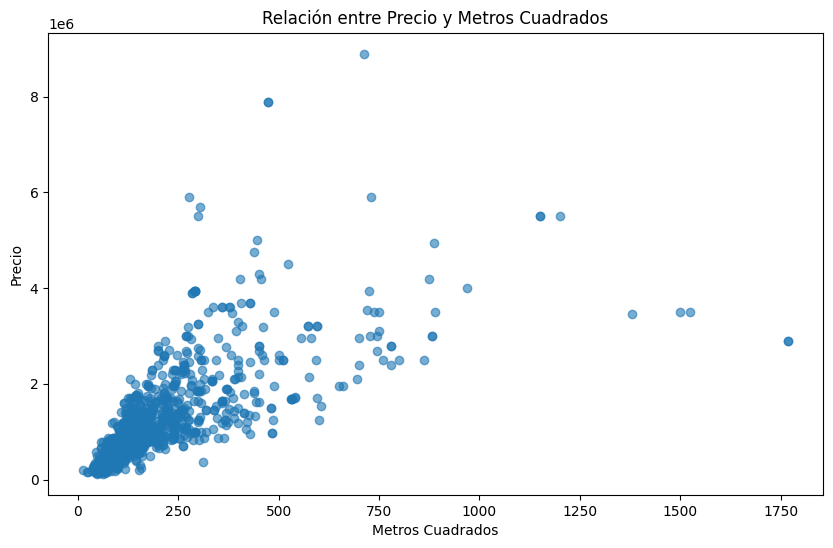

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))

plt.scatter(
    X["metros_cuadrados"],
    X["precio"],
    alpha=0.6
)

plt.xlabel("Metros Cuadrados")
plt.ylabel("Precio")
plt.title("Relación entre Precio y Metros Cuadrados")

plt.show()


# 8. Escalamiento de Datos

Las variables se normalizan para evitar que aquellas con valores más altos dominen el proceso de agrupamiento.

In [11]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

# 9. Determinación del Número Óptimo de Clusters

Se aplica el Método del Codo para determinar el valor más adecuado de K.

In [12]:
from sklearn.cluster import KMeans

inercias = []

for k in range(1, 11):

    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    modelo.fit(X_scaled)

    inercias.append(modelo.inertia_)

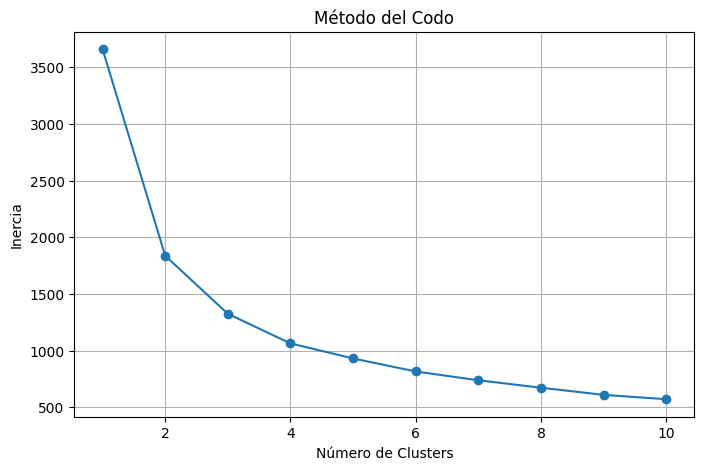

In [13]:
plt.figure(figsize=(8,5))

plt.plot(
    range(1,11),
    inercias,
    marker="o"
)

plt.xlabel("Número de Clusters")
plt.ylabel("Inercia")
plt.title("Método del Codo")

plt.grid(True)

plt.show()

# 10. Entrenamiento del Modelo K-Means

Se construye el modelo utilizando el número óptimo de clusters identificado.

In [14]:
modelo = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df["cluster"] = modelo.fit_predict(
    X_scaled
)

# 11. Caracterización de los Clusters

Se analizan las características promedio de las viviendas asignadas a cada grupo.

In [15]:
df.groupby("cluster")[
    [
        "precio",
        "metros_cuadrados",
        "habitaciones",
        "baños"
    ]
].mean().round(2)

,precio,metros_cuadrados,habitaciones,baños
cluster,,,,
0,1580661.71,256.29,4.33,3.61
1,3387052.63,621.95,5.95,5.99
2,683256.70,111.59,2.40,1.82


# 12. Distribución de Viviendas por Cluster

In [16]:
df["cluster"].value_counts()

cluster
2    487
0    333
1     95
Name: count, dtype: int64

# 13. Visualización de los Clusters

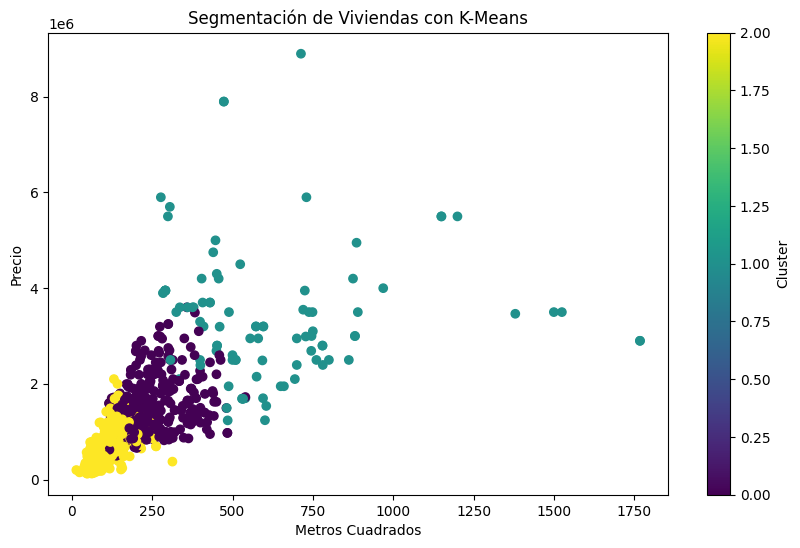

In [17]:
plt.figure(figsize=(10,6))

plt.scatter(
    df["metros_cuadrados"],
    df["precio"],
    c=df["cluster"],
    cmap="viridis"
)

plt.xlabel("Metros Cuadrados")
plt.ylabel("Precio")
plt.title("Segmentación de Viviendas con K-Means")

plt.colorbar(label="Cluster")

plt.show()


# 14. Interpretación de Resultados


La aplicación del algoritmo K-Means permitió identificar tres segmentos diferenciados de viviendas a partir de las variables precio, metros cuadrados, número de habitaciones y número de baños.

Al observar la gráfica de segmentación, se aprecia una tendencia positiva entre el tamaño de la vivienda y su precio. En términos generales, a medida que aumentan los metros cuadrados, también tiende a incrementarse el valor del inmueble.

## Cluster 0

Este grupo concentra viviendas de tamaño y precio intermedio. Se caracteriza por presentar una alta densidad de registros, lo que sugiere que representa gran parte del mercado inmobiliario analizado.

Las viviendas de este cluster poseen áreas moderadas y precios medios, por lo que pueden considerarse inmuebles dirigidos a compradores con presupuestos intermedios.

## Cluster 1

Este segmento agrupa las viviendas de mayor tamaño y mayor valor económico. En la gráfica se observa que incluye propiedades con áreas superiores a los 500 metros cuadrados e incluso algunos inmuebles que superan los 1.000 metros cuadrados.

Asimismo, este cluster contiene los precios más altos del conjunto de datos, por lo que puede interpretarse como el segmento de viviendas premium o de alta gama.

## Cluster 2

Este grupo reúne los inmuebles de menor tamaño y menor precio. Se ubica principalmente en la zona inferior izquierda de la gráfica, evidenciando una concentración de viviendas más económicas y con áreas reducidas.

Este segmento podría representar opciones de vivienda orientadas a compradores con presupuestos más limitados o propiedades de menor tamaño dentro del mercado.

## Análisis General

Los resultados muestran que el algoritmo fue capaz de identificar patrones y diferencias significativas entre los inmuebles analizados. La segmentación evidencia la existencia de tres perfiles claramente diferenciados:

- Viviendas económicas.
- Viviendas de valor medio.
- Viviendas premium.

Aunque el tamaño de la vivienda es un factor importante en la determinación del precio, la dispersión observada indica que existen otros factores que también influyen en el valor de los inmuebles, como la ubicación, la tipología, las características internas y los servicios disponibles.

# Conclusión de Negocio

La segmentación obtenida mediante K-Means permite comprender mejor la estructura del mercado inmobiliario analizado, facilitando la identificación de grupos homogéneos de viviendas. Esta información puede ser utilizada para apoyar procesos de valoración, estrategias comerciales, análisis de mercado y toma de decisiones basadas en datos.

generacion reporte 

In [18]:
reportes = Reportes()

ruta_reporte = reportes.reporte_kmeans(
    df=df,
    modelo=modelo,
    variables=[
        "precio",
        "metros_cuadrados",
        "habitaciones",
        "baños"
    ]
)

print(ruta_reporte)

Reporte guardado en: reportes/reporte_kmeans.txt
reportes/reporte_kmeans.txt
